# Customer Retention & Experimentation Platform
## Milestone 1 — a synthetic randomized experiment

**After the World Cup brings in free-trial customers, which action improves paid retention enough to be worth its cost?**

A fictional streaming service, **StreamSphere**, attracts trial users around the 2026 World Cup (June 11–July 19). Shortly before their trials end, it can do nothing special, recommend relevant non-World-Cup content, or discount the first paid month.

This notebook defines that scenario and generates experiment data. Paid retention is the primary outcome; conversion is secondary. We inspect retention alongside subscription revenue and offer costs so the later analysis can examine the tradeoff. We do not decide which action wins yet.

All people, behavior, effects, and costs are invented learning assumptions, not discoveries about real customers. We stop before formal A/B testing, ML targeting, uplift modeling, and dbt. The full specification lives in [`docs/assumptions.md`](../docs/assumptions.md).


### 1. Set up the notebook

Run cells from top to bottom. Locally, install `requirements.txt` from the repository root, start Jupyter Lab, and open this notebook. The next cell finds the repository whether Jupyter starts in the root or in `notebooks/`.

**Google Colab:** clone this repository using its actual GitHub URL in a setup cell, then `%cd /content/Customer-decisioning-platform` and run `%pip install -r requirements.txt`. Open this notebook in Colab and run all cells after setup. Alternatively upload the notebook and the `retention/` folder to the same working directory. A notebook upload alone does not include its imported module. Colab's existing NumPy/pandas/Matplotlib are sufficient for the analysis cells.

The Python module holds reusable generation and validation functions. The explanations and inspection stay here. A fixed seed reproduces a run within the same package versions; different seeds create different experiments.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'retention' / 'simulation.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Clone the repository or upload retention/ beside the notebook, then change to that directory.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from retention.simulation import ARMS, PRE_OFFER_FEATURES, simulate_experiment, validate_experiment

N_CUSTOMERS = 12_000
SEED = 2026
print(f'{N_CUSTOMERS:,} customers; seed={SEED}')
print(f'NumPy {np.__version__}; pandas {pd.__version__}')


12,000 customers; seed=2026
NumPy 2.3.5; pandas 2.2.3


### 2. Define eligibility, assignment, and the common clock

One row is one randomized customer. Signups run **May 28–July 5, 2026**, with scheduled 14-day trial ends on June 11–July 19. World-Cup-related viewing includes pre-tournament coverage and previews as well as matches.

We offer an action on **trial day 13**, one day before the scheduled trial end. Eligible customers are still active (at least one viewing-active day in the preceding three completed days) and **have not canceled**. The generator directly creates an eligible cohort; it does not simulate every signup or measure the proportion that becomes eligible. Early cancellations, inactive users, repeat accounts, and existing subscribers are outside this population. The audit flags record this eligibility explicitly.

All feature behavior comes from the **13 completed trial days before the offer**, in `[signup_date, assignment_date)`. The exclusive feature cutoff is recorded as `feature_window_end_date`. No viewing after the offer is used as a possible future ML input.

An independent random stream assigns each eligible customer to exactly one of three groups with probability **1/3**. No behavior-based targeting, exact-count balancing, noncompliance, or cross-customer spillovers are simulated.

| Group | Action | Fictional offer cost |
|---|---|---|
| No special offer (`control`) | Standard $15/month subscription | $0 |
| Content recommendation (`content_recommendation`) | Recommend relevant non-World-Cup movies, series, and other continuing content; same plan and price | $0.10 delivery cost for every assigned customer |
| Discount (`discount_20pct`) | 20% off the first paid month (30 days); standard price thereafter | Forgone subscription revenue, at most $3 per converter |

**Primary outcome:** `retained_day90` means converted and still paying **90 days after scheduled trial end**. Use **all randomized customers in each arm** as the denominator, including nonconverters. The trial-end clock is identical across groups. Follow-up ends 91 days after assignment, because assignment precedes trial end by one day.

**Secondary outcome:** `converted` means conversion by scheduled trial end. In this simple generator, successful customers start paying exactly at trial end (`conversion_day = 0` relative to that end); others never convert later. Everyone has full follow-up, without censoring or reactivation.


### 3. Generate behavior and varied offer responses

The generator draws unobserved engagement, World Cup interest, and price sensitivity between 0 and 1. These latent preferences drive the synthetic world, but are **not exported as customer features**.

* **Activity:** one recent active day is guaranteed for eligibility; other recent and earlier active days are random. Total active days cannot exceed 13.
* **Viewing:** watch hours are active days times a positive random viewing intensity. World Cup share reflects the customer's interest; `non_world_cup_hours_pre` records viewing outside that content.
* **Content breadth:** the number of distinct non-World-Cup categories watched (0–5). More varied viewing generally accompanies lower World Cup dependence.
* **Pricing visits:** a noisy observable proxy for unobserved price sensitivity, not a direct measurement of willingness to pay.
* **Discovery sessions:** pre-offer exploration beyond World Cup content, bounded by active days.

Higher activity raises baseline conversion and retention. Price sensitivity lowers baseline conversion. World Cup dependence lowers baseline retention because the tournament's appeal may not continue.

**Effects are varied, not uniformly beneficial.** Content recommendations have positive effects for World-Cup-heavy users (latent interest above 0.55), but can irritate or distract those who already explore other content (below 0.55). Discounts help sufficiently price-sensitive users (above 0.60), but can create skepticism or promotional-price expectations for others (below 0.60). At the threshold the corresponding effect is zero. These are **planted synthetic assumptions**, not empirical conclusions.

For reproducibility, the baseline conversion score is `−1.5 + 0.15 × active days + 0.025 × watch hours − 0.9 × price sensitivity`. Conditional retention score is `−0.2 + 0.12 × active days − 1.3 × World Cup interest`. Scores become probabilities using `1 / (1 + exp(−score))`.

| Action | Addition to conversion score | Addition to conditional retention score |
|---|---|---|
| No special offer | 0 | 0 |
| Content recommendation | `1.2 × (World Cup interest − 0.55)` | `2.2 × (World Cup interest − 0.55)` |
| Discount | `1.5 × (price sensitivity − 0.60)` | `0.7 × (price sensitivity − 0.60)` |

Conversion is a random yes/no draw under the assigned action. Converters receive a random cancellation time from a constant daily churn hazard calibrated to their conditional day-90 probability. No average winner is guaranteed. We do not observe the other actions' realized outcomes for that customer.

Daily churn is a simplification: there is no tournament-end churn spike, real viewing schedule, country effect, seasonal trend, missing data, or billing failure. See the assumptions document for the exact behavior distributions and limitations.


In [2]:
customers, oracle_answer_key = simulate_experiment(N_CUSTOMERS, SEED)
print(f'Observed dataset: {customers.shape}; separate answer key: {oracle_answer_key.shape}')
display(customers[['customer_id', 'assignment_date', 'scheduled_trial_end_date',
                   'followup_end_date', 'active_at_offer', 'canceled_before_offer',
                   'eligible_at_offer', 'assigned_offer']].head())
display(customers[['customer_id', *PRE_OFFER_FEATURES]].head())


Observed dataset: (12000, 29); separate answer key: (36000, 5)


,customer_id,assignment_date,scheduled_trial_end_date,followup_end_date,active_at_offer,canceled_before_offer,eligible_at_offer,assigned_offer
0,customer_0000001,2026-07-06,2026-07-07,2026-10-05,True,False,True,discount_20pct
1,customer_0000002,2026-06-23,2026-06-24,2026-09-22,True,False,True,discount_20pct
2,customer_0000003,2026-07-14,2026-07-15,2026-10-13,True,False,True,content_recommendation
3,customer_0000004,2026-07-17,2026-07-18,2026-10-16,True,False,True,control
4,customer_0000005,2026-07-10,2026-07-11,2026-10-09,True,False,True,control


,customer_id,active_days_pre,active_days_last3_pre,watch_hours_pre,world_cup_share_pre,non_world_cup_hours_pre,content_breadth_pre,pricing_page_visits_pre,discovery_sessions_pre
0,customer_0000001,9,2,21.88,0.886,2.49,2,2,1
1,customer_0000002,5,3,11.01,0.577,4.66,5,2,2
2,customer_0000003,7,3,8.07,0.242,6.12,4,4,6
3,customer_0000004,9,2,9.24,0.626,3.46,4,2,4
4,customer_0000005,11,3,6.23,0.931,0.43,2,1,0


The first preview shows eligibility and dates; the second shows behavior available before the offer. Audit flags, assignment, IDs, dates, and outcomes support experiment analysis but are excluded from the future model feature allowlist.

The **separate answer key has three rows per customer**, with probabilities under every possible action: conversion, retention conditional on conversion, and unconditional retention (their product). This is simulation ground truth for later method checks, **not information available to a real prediction model**. It contains probabilities rather than realized counterfactual outcomes. Never use it as customer features or training inputs.


In [3]:
# Explicit feature boundary for a future milestone; no model is trained here.
pre_offer_features = customers.loc[:, list(PRE_OFFER_FEATURES)].copy()
assert not any(c.startswith('p_') for c in customers.columns)
assert set(pre_offer_features.columns) == set(PRE_OFFER_FEATURES)
print('Baseline feature columns:', ', '.join(pre_offer_features.columns))


Baseline feature columns: active_days_pre, active_days_last3_pre, watch_hours_pre, world_cup_share_pre, non_world_cup_hours_pre, content_breadth_pre, pricing_page_visits_pre, discovery_sessions_pre


### 4. Understand subscription revenue and offer costs

Revenue accrues during the common 90-day window `[scheduled_trial_end_date, followup_end_date)`. A month is 30 days, so the list price is **$0.50/day**. A cancellation after `k` paid intervals earns `k` days of revenue, up to 90; retained users earn the whole window. Cancellation exactly at the day-90 boundary counts as not retained, even though 90 days can have accrued. This is prorated revenue, not upfront nonrefundable monthly billing.

`reference_revenue_90` = paid days × $0.50 before discounts.

`discount_cost_90` = 20% × $0.50 × first min(30, paid days), only for discount-arm converters. `subscription_revenue_90` = reference revenue − discount cost: **subscription revenue after discounts**.

`delivery_cost_90` = $0.10 for every content recommendation assignment, otherwise zero. `offer_cost_90` = discount cost + delivery cost. The supplementary `revenue_less_delivery_cost_90` = subscription revenue − delivery cost.

Do not subtract total offer cost from subscription revenue: the discount is already accounted for there. Nonconverting recommendation users have zero subscription revenue but still incur delivery cost.

These are **revenue** and incremental offer-cost metrics, not profit. Acquisition, licensing, baseline hosting, taxes, refunds, fixed costs, and other operating expenses are omitted. The business question involves both retention and economic value; this milestone establishes the data to examine it later.


In [4]:
ledger_columns = ['assigned_offer', 'converted', 'retained_day90', 'conversion_day',
                  'paid_days_90', 'reference_revenue_90', 'discount_cost_90',
                  'subscription_revenue_90', 'delivery_cost_90', 'offer_cost_90',
                  'revenue_less_delivery_cost_90']
# Show a converter and nonconverter per group without dumping the dataset.
display(customers.groupby(['assigned_offer', 'converted'], sort=False).head(1)[ledger_columns].round(2))


,assigned_offer,converted,retained_day90,conversion_day,paid_days_90,reference_revenue_90,discount_cost_90,subscription_revenue_90,delivery_cost_90,offer_cost_90,revenue_less_delivery_cost_90
0,discount_20pct,False,False,NaN,0,0.0,0.0,0.0,0.0,0.0,0.0
1,discount_20pct,True,False,0.0,63,31.5,3.0,28.5,0.0,3.0,28.5
2,content_recommendation,False,False,NaN,0,0.0,0.0,0.0,0.1,0.1,-0.1
3,control,False,False,NaN,0,0.0,0.0,0.0,0.0,0.0,0.0
11,content_recommendation,True,True,0.0,90,45.0,0.0,45.0,0.1,0.1,44.9
14,control,True,False,0.0,36,18.0,0.0,18.0,0.0,0.0,18.0


### 5. Check that the simulator obeys the design

These checks catch ineligible users, behavior outside the pre-offer window, broken IDs and dates, retention without conversion, invalid oracle probabilities, leaked probability columns, and incorrect revenue or offer costs. They verify data integrity rather than whether a particular action wins.


In [5]:
validate_experiment(customers, oracle_answer_key)
print('Timeline, outcome, oracle separation, and revenue checks passed.')


Timeline, outcome, oracle separation, and revenue checks passed.


### 6. Inspect randomization and pre-offer balance

Each arm should receive about a third of the cohort. The table compares baseline behavior before any offer can affect it. Small differences are normal random variation. For a readable scale comparison, the second table expresses each arm's deviation from the overall mean in units of the overall feature standard deviation; zero means exact equality. This is a simulator diagnostic, not a hypothesis test or a reason to rerandomize until balance looks perfect.


,customers,share
assigned_offer,,
control,3999,0.333
content_recommendation,3970,0.331
discount_20pct,4031,0.336


,active_days_pre,active_days_last3_pre,watch_hours_pre,world_cup_share_pre,non_world_cup_hours_pre,content_breadth_pre,pricing_page_visits_pre,discovery_sessions_pre
assigned_offer,,,,,,,,
control,7.06,2.01,9.26,0.59,3.77,2.62,1.54,2.88
content_recommendation,7.00,2.01,8.96,0.60,3.59,2.62,1.57,2.82
discount_20pct,6.99,2.02,9.08,0.60,3.66,2.63,1.56,2.83


,active_days_pre,active_days_last3_pre,watch_hours_pre,world_cup_share_pre,non_world_cup_hours_pre,content_breadth_pre,pricing_page_visits_pre,discovery_sessions_pre
assigned_offer,,,,,,,,
control,0.016,-0.003,0.021,-0.012,0.026,-0.004,-0.010,0.017
content_recommendation,-0.006,-0.003,-0.018,0.008,-0.022,-0.003,0.011,-0.010
discount_20pct,-0.010,0.006,-0.003,0.004,-0.004,0.007,-0.001,-0.007


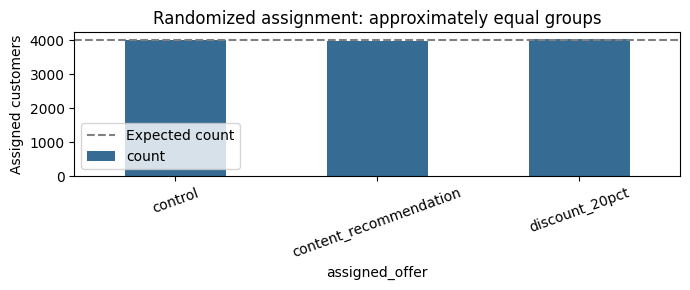

In [6]:
counts = customers.assigned_offer.value_counts().reindex(ARMS)
balance = customers.groupby('assigned_offer')[list(PRE_OFFER_FEATURES)].mean().reindex(ARMS)
display(pd.DataFrame({'customers': counts, 'share': counts / N_CUSTOMERS}).round(3))
display(balance.round(2))
standardized_deviations = (balance - customers[list(PRE_OFFER_FEATURES)].mean()) / customers[list(PRE_OFFER_FEATURES)].std()
display(standardized_deviations.round(3))
counts.plot.bar(color='#366b93', figsize=(7, 3), rot=20)
plt.axhline(N_CUSTOMERS / len(ARMS), color='gray', linestyle='--', label='Expected count')
plt.ylabel('Assigned customers')
plt.title('Randomized assignment: approximately equal groups')
plt.legend()
plt.tight_layout()
plt.show()


### 7. Inspect primary retention, secondary conversion, and economics

All rates and average dollars use **all randomized customers in each arm**, including nonconverters. The primary outcome is paid retention at scheduled trial end + 90 days. Conversion by trial end is secondary. Retention cannot exceed conversion.

The table and charts show how retention, subscription revenue after discounts, and offer costs can move differently. Recommendations cost money even without conversion. Discounts reduce revenue for converted users, including customers who might have paid without one. Stronger conversion alone does not answer whether an action is worth its cost.

These are **descriptive simulator outputs**, not statistical offer recommendations. Formal comparisons, uncertainty, and appropriate A/B testing belong to a later milestone. Retention comparisons restricted to converters would condition on a post-treatment outcome and require additional care. Changing the seed changes sampled outcomes; changing the planted assumptions changes the synthetic world.


,customers,retained_day90_rate,conversion_by_trial_end_rate,average_subscription_revenue,average_offer_cost,average_revenue_less_delivery_cost
assigned_offer,,,,,,
control,3999,0.177,0.359,11.581,0.000,11.581
content_recommendation,3970,0.180,0.357,11.788,0.100,11.688
discount_20pct,4031,0.154,0.311,9.230,0.835,9.230


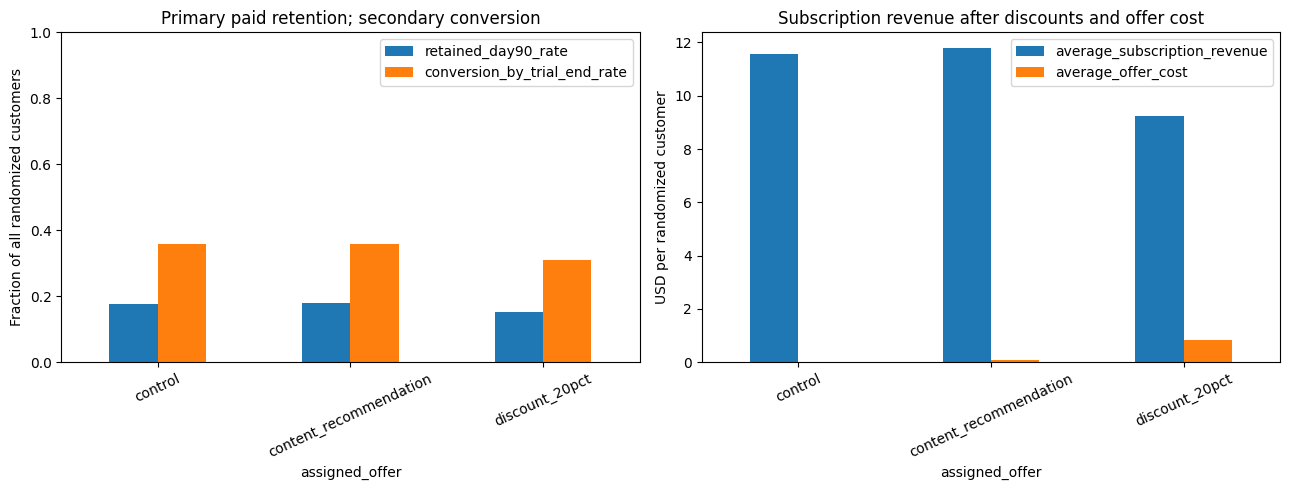

In [7]:
summary = customers.groupby('assigned_offer').agg(
    customers=('customer_id', 'size'),
    retained_day90_rate=('retained_day90', 'mean'),
    conversion_by_trial_end_rate=('converted', 'mean'),
    average_subscription_revenue=('subscription_revenue_90', 'mean'),
    average_offer_cost=('offer_cost_90', 'mean'),
    average_revenue_less_delivery_cost=('revenue_less_delivery_cost_90', 'mean'),
).reindex(ARMS)
display(summary.round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
summary[['retained_day90_rate', 'conversion_by_trial_end_rate']].plot.bar(ax=axes[0], rot=25)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel('Fraction of all randomized customers')
axes[0].set_title('Primary paid retention; secondary conversion')
summary[['average_subscription_revenue', 'average_offer_cost']].plot.bar(ax=axes[1], rot=25)
axes[1].set_ylabel('USD per randomized customer')
axes[1].set_title('Subscription revenue after discounts and offer cost')
plt.tight_layout()
plt.show()


### 8. Evaluation-only answer-key check

We now briefly open the separate answer key to check whether the simulator's random draws match their expected probabilities. We select only each customer's assigned arm and compare average expected probabilities with realized rates. They should be reasonably close, not exactly equal; individual outcomes remain random. The three-action key is kept intact for later evaluation, but is never added to `pre_offer_features` or `customers`.

This checks the data-generating process, not a trained model or an A/B-test conclusion.


In [8]:
evaluation_only = customers[['customer_id', 'assigned_offer', 'converted', 'retained_day90']].merge(
    oracle_answer_key,
    left_on=['customer_id', 'assigned_offer'], right_on=['customer_id', 'offer'],
    validate='one_to_one',
)
calibration = evaluation_only.groupby('assigned_offer').agg(
    expected_conversion=('p_conversion', 'mean'), observed_conversion=('converted', 'mean'),
    expected_retention=('p_retained_day90', 'mean'), observed_retention=('retained_day90', 'mean'),
).reindex(ARMS)
display(calibration.round(3))
del evaluation_only  # Do not carry a probability-enriched table into later training.


,expected_conversion,observed_conversion,expected_retention,observed_retention
assigned_offer,,,,
control,0.348,0.359,0.170,0.177
content_recommendation,0.359,0.357,0.186,0.180
discount_20pct,0.314,0.311,0.149,0.154


### 9. Save local data without putting it in Git

The next cell writes the observed experiment and the oracle to different folders, both under ignored `data/`. It also records the seed, sample size, and package versions. Re-running overwrites this run's local files. The notebook keeps small previews, tables, and charts, not the complete dataset in its outputs.

For later modeling, use only the explicit pre-offer feature allowlist. Customer IDs support joins; dates support cohort audits; assignment identifies treatment; outcomes are labels or experiment metrics. None of those automatically becomes a pre-offer feature. The oracle is for evaluation only, and should never be loaded into a training pipeline.


In [9]:
import json
observed_dir = ROOT / 'data' / 'generated'
oracle_dir = ROOT / 'data' / 'evaluation_only'
observed_dir.mkdir(parents=True, exist_ok=True)
oracle_dir.mkdir(parents=True, exist_ok=True)
customers.to_csv(observed_dir / 'customers.csv', index=False)
oracle_answer_key.to_csv(oracle_dir / 'oracle_probabilities.csv', index=False)
metadata = {'n_customers': N_CUSTOMERS, 'seed': SEED, 'numpy': np.__version__,
            'pandas': pd.__version__, 'followup_days': 90,
            'pre_offer_features': list(PRE_OFFER_FEATURES),
            'scenario': 'eligible_day13_three_actions_trial_end_followup',
            'arms': list(ARMS), 'assignment_probability': 1 / len(ARMS),
            'offer_day': 13, 'trial_days': 14, 'followup_anchor': 'scheduled_trial_end_date'}
(observed_dir / 'run_metadata.json').write_text(json.dumps(metadata, indent=2) + '\n')
print('Saved observed customers and a separate evaluation-only answer key under ignored data/.')


Saved observed customers and a separate evaluation-only answer key under ignored data/.


### What to inspect and what comes later

Review eligibility, the pre-offer cutoff, the trial-end follow-up clock, varied synthetic effects, and revenue accounting in [`docs/assumptions.md`](../docs/assumptions.md). Then inspect the balance and retention/revenue tables. Try a different seed or sample size and run all cells again.

The test suite (`python -m pytest -q`) checks reproducibility, small cohorts, invalid inputs, eligibility, timing, randomization, probability calibration, both helpful and harmful planted effects, and whether validation catches broken revenue or leaked probabilities.

**Milestone 1 ends here.** Later work can compare randomized actions with appropriate A/B testing, evaluate ML targeting or uplift methods, and add dbt transformations. No targeting model, uplift model, or deployment decision is implemented here.
